[1] "Tổng số ngày dữ liệu: 180"

 ARIMA(0,0,0)           with zero mean     : 1962.145
 ARIMA(0,0,0)           with non-zero mean : 1228.487
 ARIMA(0,0,0)(0,0,1)[7] with zero mean     : 1775.075
 ARIMA(0,0,0)(0,0,1)[7] with non-zero mean : 1230.362
 ARIMA(0,0,0)(0,0,2)[7] with zero mean     : 1666.319
 ARIMA(0,0,0)(0,0,2)[7] with non-zero mean : 1231.626
 ARIMA(0,0,0)(1,0,0)[7] with zero mean     : Inf
 ARIMA(0,0,0)(1,0,0)[7] with non-zero mean : 1230.388
 ARIMA(0,0,0)(1,0,1)[7] with zero mean     : Inf
 ARIMA(0,0,0)(1,0,1)[7] with non-zero mean : 1231.66
 ARIMA(0,0,0)(1,0,2)[7] with zero mean     : Inf
 ARIMA(0,0,0)(1,0,2)[7] with non-zero mean : 1233.61
 ARIMA(0,0,0)(2,0,0)[7] with zero mean     : Inf
 ARIMA(0,0,0)(2,0,0)[7] with non-zero mean : 1231.702
 ARIMA(0,0,0)(2,0,1)[7] with zero mean     : Inf
 ARIMA(0,0,0)(2,0,1)[7] with non-zero mean : 1233.61
 ARIMA(0,0,0)(2,0,2)[7] with zero mean     : Inf
 ARIMA(0,0,0)(2,0,2)[7] with non-zero mean : Inf
 ARIMA(0,0,1)           with zero

Series: ts_orders 
ARIMA(0,0,0) with non-zero mean 

Coefficients:
         mean
      55.5556
s.e.   0.5410

sigma^2 = 52.99:  log likelihood = -612.21
AIC=1228.42   AICc=1228.49   BIC=1234.81

Training set error measures:
                       ME     RMSE      MAE       MPE     MAPE      MASE
Training set 1.263169e-14 7.258881 5.690123 -1.772321 10.55419 0.7092157
                   ACF1
Training set 0.04787046


=> Mô hình được chọn chính xác là: SARIMA(0,0,0) x (0,0,0)[7]



Warning message:
“Removed 30 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 180 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 180 rows containing missing values or values outside the scale range
(`geom_ribbon()`).”


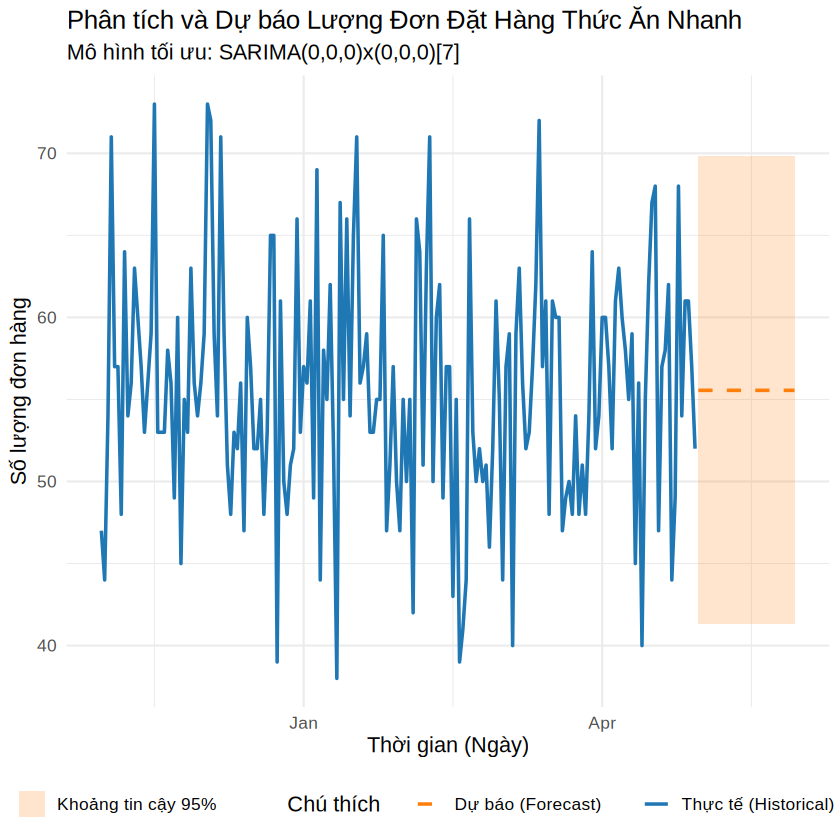

In [8]:
# 1. Cài đặt và tải các thư viện cần thiết
if (!require("forecast")) install.packages("forecast")
if (!require("tseries")) install.packages("tseries")
if (!require("ggplot2")) install.packages("ggplot2")
if (!require("dplyr")) install.packages("dplyr")
if (!require("tidyr")) install.packages("tidyr")
if (!require("lubridate")) install.packages("lubridate")

library(forecast)
library(tseries)
library(ggplot2)
library(dplyr)
library(tidyr)
library(lubridate)

# 2. Đọc và xử lý dữ liệu
df <- read.csv("cleaned_data (1).csv")

# Chuyển đổi cột thời gian và tổng hợp số lượng đơn hàng theo ngày
df$order_time <- ymd_hms(df$order_time)
df$date <- as.Date(df$order_time)

daily_orders <- df %>%
  group_by(date) %>%
  summarise(orders = n()) %>%
  complete(date = seq.Date(min(date), max(date), by="day"), fill = list(orders = 0))

# Chuyển đổi thành đối tượng chuỗi thời gian (Time Series) với chu kỳ mùa vụ theo tuần (frequency = 7)
ts_orders <- ts(daily_orders$orders, frequency = 7)

print(paste("Tổng số ngày dữ liệu:", length(ts_orders)))

# 3. Tìm tham số SARIMA tối ưu với d = 0 và D = 0
best_sarima <- auto.arima(ts_orders,
                          seasonal = TRUE,
                          d = 0,             # Cố định sai phân không mùa vụ d = 0
                          D = 0,             # Cố định sai phân mùa vụ D = 0
                          stepwise = FALSE,
                          approximation = FALSE,
                          trace = TRUE)

# --- ĐOẠN HIỂN THỊ RÕ TÊN MÔ HÌNH SARIMA ---
cat("\n========================================\n")
cat(" KẾT QUẢ MÔ HÌNH TỐI ƯU: SARIMA\n")
cat("========================================\n")
# In tóm tắt mô hình
summary(best_sarima)

# Trích xuất các bậc tham số (p,d,q) và (P,D,Q)[m]
p <- best_sarima$arma[1]
d <- best_sarima$arma[6]
q <- best_sarima$arma[2]
P <- best_sarima$arma[3]
D <- best_sarima$arma[7]
Q <- best_sarima$arma[4]
m <- best_sarima$arma[5]

cat(sprintf("\n=> Mô hình được chọn chính xác là: SARIMA(%d,%d,%d) x (%d,%d,%d)[%d]\n", p, d, q, P, D, Q, m))
cat("========================================\n\n")

# 4. Dự báo 30 ngày tiếp theo
forecast_steps <- 30
fc <- forecast(best_sarima, h = forecast_steps)

# 5. Trực quan hóa kết quả bằng ggplot2
df_plot <- data.frame(
  Date = seq.Date(min(daily_orders$date), by = "day", length.out = length(ts_orders) + forecast_steps),
  Value = c(as.numeric(ts_orders), rep(NA, forecast_steps)),
  Forecast = c(rep(NA, length(ts_orders)), as.numeric(fc$mean)),
  Lower80 = c(rep(NA, length(ts_orders)), as.numeric(fc$lower[,1])),
  Upper80 = c(rep(NA, length(ts_orders)), as.numeric(fc$upper[,1])),
  Lower95 = c(rep(NA, length(ts_orders)), as.numeric(fc$lower[,2])),
  Upper95 = c(rep(NA, length(ts_orders)), as.numeric(fc$upper[,2]))
)

p <- ggplot(df_plot, aes(x = Date)) +
  geom_line(aes(y = Value, color = "Thực tế (Historical)"), linewidth = 1) +
  geom_line(aes(y = Forecast, color = "Dự báo (Forecast)"), linewidth = 1, linetype = "dashed") +
  geom_ribbon(aes(ymin = Lower95, ymax = Upper95, fill = "Khoảng tin cậy 95%"), alpha = 0.2) +
  scale_color_manual(values = c("Thực tế (Historical)" = "#1f77b4", "Dự báo (Forecast)" = "#ff7f0e")) +
  scale_fill_manual(values = c("Khoảng tin cậy 95%" = "#ff7f0e")) +
  labs(
    title = "Phân tích và Dự báo Lượng Đơn Đặt Hàng Thức Ăn Nhanh",
    subtitle = sprintf("Mô hình tối ưu: SARIMA(%d,%d,%d)x(%d,%d,%d)[%d]", p, d, q, P, D, Q, m),
    x = "Thời gian (Ngày)",
    y = "Số lượng đơn hàng",
    color = "Chú thích",
    fill = ""
  ) +
  theme_minimal(base_size = 13) +
  theme(legend.position = "bottom")

# Hiển thị biểu đồ
print(p)

